# Rydberg Atom Ion Interaction

Here we look at the interaction between a single ion and a Rydberg atom. More details regarding the theory can be found in [A. Duspayev et al., Phys. Rev. Research 3, 023114 (2021)](https://doi.org/10.1103/PhysRevResearch.3.023114) or [M. Deiß et al., Atoms 9, 34 (2021)](https://doi.org/10.3390/atoms9020034). The internuclear axis is aligned with the z-direction and the interaction is expanded in multipolar terms. With this choice of coordinate system, the interaction potential is rotationally symmetric around the quantization axis and only states of same $m_J$ couple with each other, reducing the number of basis states.

We will reproduce here results shown in Fig. 2 in Phys. Rev. Research 3, 023114 (2021), demonstrating the influence of higher multipole order terms.

In the code below, the ``SystemAtom`` class defines the system of the Rydberg atom and the ion, including the effect of the electric field of the ion into the calculations. The charge of the ion is passed with ``SystemAtom.set_ion_charge(value, unit)`` and the distance between the ion and the Rydberg core with ``SystemAtom.set_distance_to_ion(distance, angle_degree, unit)``. We calculate the energy of the Rydberg state for different internuclear distances and including a different number of multipole orders. Choosing a maximum multipole order of two is equivalent to calculating a Stark Map in a homogeneous electric field.

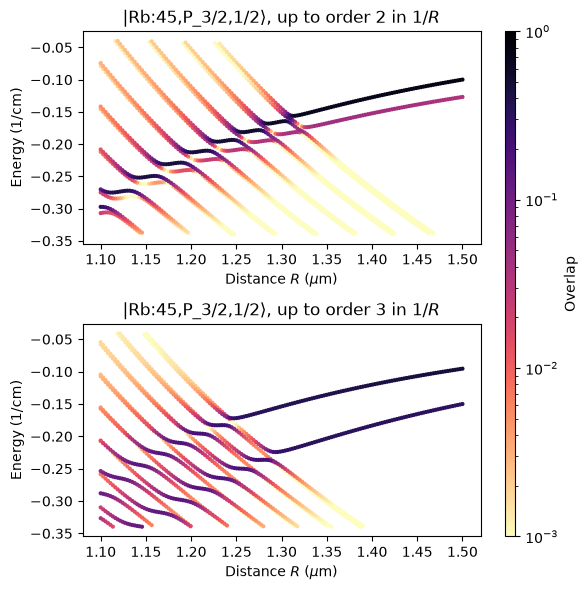

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pairinteraction as pi

if pi.Database.get_global_database() is None:
    pi.Database.initialize_global_database(download_missing=True)

# Define the Rydberg state for which the interaction with the ion should be calculated
ket = pi.KetAtom("Rb", n=45, l=1, j=1.5, m=0.5)
energy = ket.get_energy(unit="1/cm")

# Setup basis, considering states only with similar energy and principal quantum number (if a
# high accuracy is required, the energy and principal quantum number ranges must be increased).
# Since the ion and Rydberg atom are placed on the z-axis, the magnetic quantum number is
# conserved.
basis = pi.BasisAtom.from_kets(
    ket, delta_n=3, delta_m=0, delta_energy=4, delta_energy_unit="1/cm"
)

fig = plt.figure(figsize=(6, 6))
axs = fig.subplots(2, 1)

# Setup system
# Define the maximum considered order of the multipole expansion.
# 2: monopole-dipole (scales like 1/R^2 with the distance R),
# 3: monopole-quadrupole (scales like 1/R^3), ...
distances = np.linspace(1.1, 1.5, 150)
for order, ax in zip([2, 3], axs, strict=True):
    systems = [
        pi.SystemAtom(basis)
        .set_ion_charge(1, unit="e")
        .set_ion_interaction_order(order)
        .set_distance_to_ion(d, unit="micrometer")
        for d in distances
    ]

    # Diagonalize the system
    pi.diagonalize(
        systems,
        diagonalizer="lapacke_evr",
        energy_range=(energy - 0.34, energy - 0.04),
        energy_range_unit="1/cm",
    )

    # Get eigenenergies and overlaps
    list_eigenenergies = [system.get_eigenenergies(unit="1/cm") for system in systems]
    list_overlaps = [system.get_eigenbasis().get_overlaps(ket) for system in systems]
    list_distances = [
        d * np.ones_like(e) for d, e in zip(distances, list_eigenenergies, strict=True)
    ]

    # Sort so that the potential curves with largest overlap are plotted on top
    list_eigenenergies = np.hstack(list_eigenenergies)
    list_overlaps = np.hstack(list_overlaps)
    list_distances = np.hstack(list_distances)

    sorter = np.argsort(list_overlaps)
    list_distances = list_distances[sorter]
    list_eigenenergies = list_eigenenergies[sorter]
    list_overlaps = list_overlaps[sorter]

    # Plot the potential curves
    ax.set_title(rf"{ket}, up to order {order} in $1/R$")
    scat = ax.scatter(
        list_distances,
        list_eigenenergies - energy,
        c=list_overlaps,
        s=4,
        vmin=1e-3,
        vmax=1,
        norm="log",
        cmap="magma_r",
    )
    ax.set_xlabel(r"Distance $R$ ($\mu$m)")
    ax.set_ylabel("Energy (1/cm)")

fig.tight_layout()
fig.colorbar(scat, label="Overlap", ax=axs, aspect=50)
plt.show()